# Machine Learning Challenge (Individual Assignment, 30%)


<div class="alert-danger">

**Your name:** Brennan Chan 

</div>

## Introduction

Develop a model to predict the numerical target `Y` from anonymous, synthetic features. Your test predictions are evaluated using **mean absolute error (MAE)**; lower is better.

Read [ReadMe.md](ReadMe.md) for the full assignment rules, grading criteria, file descriptions, and required deliverables. **Submit by 15 December 2026 via [Canvas](https://canvas.esmt.berlin/courses/794/assignments/11053).**

Use this notebook to develop and document your solution. The cells below provide data-loading helpers, baseline forecasts, and submission generation.


## Preliminaries
Imports of standard libraries are included below. Add any further imports below and use `SEED` for reproducible random operations.

Keep `train_X.csv`, `train_y.csv`, and `test_X.csv` in the same folder as this notebook, or adjust `DATA_DIR` before running the helper definitions.

- `load_training_data()` returns `X` and `y`, aligned by `ID`; IDs are excluded from the model features.
- `load_test_data()` returns test features with IDs in the index.
- `write_submission(test_ids, predictions, filename)` writes columns `ID` and `Y`, preserving the supplied ID/prediction order.


In [20]:
# Standard library imports
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

# Add more imports if needed. You can use any Python library and ML algorithm

SEED = 67
DATA_DIR = Path('.') # adjust if you store the data 

In [2]:
def load_training_data(data_dir=DATA_DIR):
    """Return training features X and targets y, aligned by case ID."""
    data_dir = Path(data_dir)
    # ID becomes the row index and is excluded from the model's feature columns.
    X = pd.read_csv(data_dir / 'train_X.csv', index_col='ID')
    targets = pd.read_csv(data_dir / 'train_y.csv', index_col='ID')
    # Match target rows to feature IDs even if the label file has been reordered.
    y = targets.loc[X.index, 'Y']
    return X, y

In [3]:
def load_test_data(data_dir=DATA_DIR):
    """Return unlabeled test features, retaining case IDs as the row index."""
    return pd.read_csv(Path(data_dir) / 'test_X.csv', index_col='ID')

In [4]:
def write_submission(test_ids, predictions, filename='submission.csv'):
    """Write ID and target Y to a CSV; predictions follow the supplied ID order."""
    ids = pd.Index(test_ids, name='ID')
    # An array prevents pandas from silently aligning a prediction Series by index.
    predictions = np.asarray(predictions, dtype=float)
    if predictions.shape != (len(ids),):
        raise ValueError('Provide one prediction per test ID as a one-dimensional array or Series.')
    if ids.has_duplicates or ids.isna().any():
        raise ValueError('Test IDs must be unique and non-missing.')
    if not np.isfinite(predictions).all():
        raise ValueError('Predictions must contain only finite numerical values.')

    submission = pd.DataFrame({'Y': predictions}, index=ids)
    output_path = Path(filename)
    # Write the index exactly once as the ID column, followed by target column Y.
    submission.to_csv(output_path, index_label='ID')
    return output_path

## Your solution

Add code and Markdown cells below to develop and explain your approach. Compare models using validation data drawn from the training sample; fit learned preprocessing only on the relevant training rows. Keep features and targets aligned.

The starter code compares linear regression with a constant forecast equal to the target mean. Its **in-sample MAEs** illustrate training fit; use validation to assess performance on unseen cases.

After selecting your procedure, fit it on the available training data and assign the fitted predictor to `final_model`. The baseline already uses this name, so you can run the submission cell immediately.

Do not forget that any preprocessing of the training data must be performed on the test data before you can apply for final model.


In [33]:
# Load the training data
X, y = load_training_data()

# Fit linear regression and evaluate its predictions in-sample
final_model = LinearRegression()
final_model.fit(X, y)
training_predictions = final_model.predict(X)
regression_mae = mean_absolute_error(y, training_predictions)

# Compare against a constant forecast equal to the target's mean (over training data)
target_mean = y.mean()
mean_predictions = np.full(len(y), target_mean)
mean_mae = mean_absolute_error(y, mean_predictions)

print(f'Training target mean: {target_mean:.3f}')
print(f'Mean forecast MAE (in-sample): {mean_mae:.3f}')
print(f'Linear regression MAE (in-sample): {regression_mae:.3f}')

Training target mean: 197.901
Mean forecast MAE (in-sample): 101.619
Linear regression MAE (in-sample): 40.655


### Time to develop your solution

In [34]:
# Your code goes here ...
from sklearn.metrics import root_mean_squared_error, r2_score

# Create an evaluation function to evaluate the created model 
def evaluate(name, y_true, y_pred):
    return {'model': name,
            'MAE':  mean_absolute_error(y_true, y_pred),
            'RMSE': root_mean_squared_error(y_true, y_pred),
            'R2':   r2_score(y_true, y_pred)}

count    1875.000000
mean      197.901240
std       109.123402
min        17.346214
25%        95.241473
50%       188.942538
75%       300.362426
max       383.855360
Name: Y, dtype: float64
Skew: 0.015 | Unique values: 1875


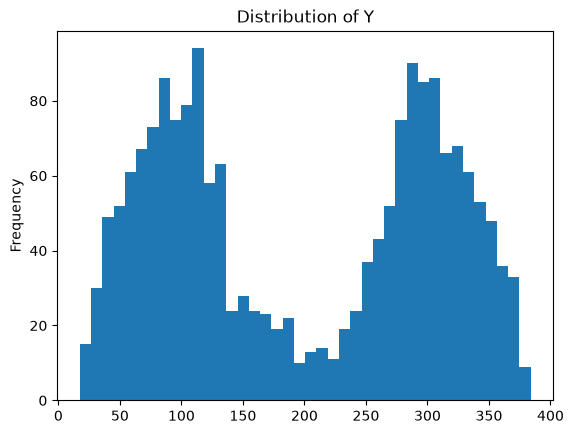

Missing values: 0 | Duplicate rows: 0


,mean,std,min,max,n_unique,skew,outliers_3sd,corr_Y,spearman_Y,train_vs_test_p
X4,21.213,119.319,-297.669,356.663,1875,0.017,0,-0.544,-0.545,0.639
X15,-1174.150,4674.909,-9523.957,11667.710,1875,0.122,0,-0.508,-0.509,0.327
X36,0.178,16.976,-62.620,58.409,1875,-0.032,10,-0.413,-0.427,0.104
X10,16.957,12.231,-32.669,71.648,1875,0.570,18,-0.320,-0.312,0.403
X16,-1.091,364.079,-797.791,763.496,1875,0.000,0,-0.305,-0.304,0.387
X31,1.365,24.407,-79.360,81.264,1875,-0.001,6,-0.280,-0.284,0.620
X29,131.398,270.189,-110.831,1432.465,1875,1.555,28,-0.253,-0.258,0.562
X47,22.163,24.109,-81.355,85.701,1875,-0.533,9,0.224,0.207,0.888
X40,98.860,0.731,94.424,99.984,1875,-1.670,36,0.215,0.331,0.261
X9,1971.480,2761.181,-7507.584,8799.492,1875,-0.671,6,-0.210,-0.192,0.356


Redudant Feature Pairs
X39  X45    0.945
X4   X15    0.870
X29  X31    0.867
X15  X36    0.761
X5   X9     0.741
X18  X32    0.737
X16  X18    0.713
X4   X36    0.647
X16  X45    0.600
X9   X19    0.582
dtype: float64
Rows at X46 max: 1091


In [35]:
X_test_raw = load_test_data()

# Target
print(y.describe())
print('Skew:', round(stats.skew(y), 3), '| Unique values:', y.nunique())
y.plot.hist(bins=40, title='Distribution of Y'); plt.show()

# Feature summary
summary = pd.DataFrame({
    'mean': X.mean(), 'std': X.std(), 'min': X.min(), 'max': X.max(),
    'n_unique': X.nunique(), 'skew': X.skew(),
    'outliers_3sd': ((X - X.mean()).abs() > 3 * X.std()).sum(),
    'corr_Y': X.corrwith(y),
    'spearman_Y': X.corrwith(y, method='spearman'),
    'train_vs_test_p': [stats.ks_2samp(X[c], X_test_raw[c]).pvalue for c in X]})
print('Missing values:', X.isna().sum().sum(), '| Duplicate rows:', X.duplicated().sum())
display(summary.round(3).sort_values('corr_Y', key=abs, ascending=False))

# Most redundant feature pairs
corr = X.corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print("Redudant Feature Pairs\n", pairs.sort_values(ascending=False).head(10).round(3), sep = "")

# Capped values in X46
print('Rows at X46 max:', np.isclose(X['X46'], X['X46'].max()).sum())

In [36]:
# lets create a Train, Validation AND Holdout split
X_temp, X_holdout, y_temp, y_holdout = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=SEED)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, 
    y_temp, 
    test_size=0.25, 
    random_state=SEED) 

# check the size of the splits 
print(f'Train: {len(X_train)} | Validation: {len(X_val)} | Holdout: {len(X_holdout)}')

Train: 1125 | Validation: 375 | Holdout: 375


In [37]:
# Shared CV setup
X_dev = pd.concat([X_train, X_val]) 
y_dev = pd.concat([y_train, y_val])
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

# find the boundary between the 2 bumps 
y_arr = y_dev.values

# define the 2 bumps and find the likelihood something is from a certian bump
gmm = GaussianMixture(n_components=2, random_state=SEED).fit(y_arr.reshape(-1, 1))
order = np.argsort(gmm.means_.ravel())               
print('Means:', gmm.means_.ravel()[order].round(1),
      '| SDs:', np.sqrt(gmm.covariances_.ravel()[order]).round(1),
      '| Weights:', gmm.weights_[order].round(3))

grid = np.linspace(100, 300, 2001)
p_high_grid = gmm.predict_proba(grid.reshape(-1, 1))[:, order[1]]
gmm_cutoff = grid[np.argmin(np.abs(p_high_grid - 0.5))]

kde_grid = np.linspace(120, 280, 1601)
kde_min = kde_grid[np.argmin(gaussian_kde(y_arr)(kde_grid))]

print(f'GMM boundary (P(high) = 0.5): {gmm_cutoff:.1f}')
print(f'KDE density minimum (independent check): {kde_min:.1f}')
print('Ambiguous zone (P(high) between 0.2 and 0.8):',
      grid[(p_high_grid > 0.2) & (p_high_grid < 0.8)][[0, -1]].round(0))

CUTOFF = round(gmm_cutoff)  
print(f'CUTOFF = {CUTOFF}')

Means: [ 98.8 301.1] | SDs: [41.4 39.2] | Weights: [0.512 0.488]
GMM boundary (P(high) = 0.5): 202.7
KDE density minimum (independent check): 204.8
Ambiguous zone (P(high) between 0.2 and 0.8): [192. 214.]
CUTOFF = 203


In [38]:
# create simple baselines to get a better understanding of the default models 
results = []

# constant forecast (training mean only, no peeking at validation)
results.append(evaluate('Mean forecast', y_val, np.full(len(y_val), y_train.mean())))

# linear regression from the example but tested against the validation set to
lr = LinearRegression().fit(X_train, y_train)
results.append(evaluate('Linear regression', y_val, lr.predict(X_val)))

# Baseline 3: untuned random forest (regression, not classification)
rf = RandomForestRegressor(random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)
results.append(evaluate('Random forest (untuned)', y_val, rf.predict(X_val)))

pd.DataFrame(results).set_index('model').round(3)

,MAE,RMSE,R2
model,,,
Mean forecast,99.568,107.569,-0.014
Linear regression,41.968,50.478,0.777
Random forest (untuned),54.424,67.278,0.604


Ok now that we have a better understanding of the data we can see that the data is divided into 2 normal distributions so why not have 2 models to predict each side of the distribution and then classify which side it is on after.

Just have mutli modality

In [27]:
# import dump 
from sklearn.model_selection import KFold, cross_validate
from sklearn.preprocessing import StandardScaler, SplineTransformer, PolynomialFeatures
from sklearn.linear_model import RidgeCV, LassoCV, HuberRegressor, QuantileRegressor, LogisticRegression, LogisticRegressionCV

from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import accuracy_score, roc_auc_score, mean_absolute_error
from xgboost import XGBClassifier
from sklearn.mixture import GaussianMixture
from scipy.stats import gaussian_kde

In [ ]:
alphas = np.logspace(-3, 3, 30)

# Candidate regressors for inside each bump
candidates = {
    'Linear regression': LinearRegression(),
    'Ridge': make_pipeline(StandardScaler(), 
                           RidgeCV(alphas=alphas)),
    'Lasso': make_pipeline(StandardScaler(), 
                           LassoCV(random_state=SEED, max_iter=50000)),
    'Huber': make_pipeline(StandardScaler(), 
                           HuberRegressor(max_iter=5000)),
    'Median regression': make_pipeline(StandardScaler(),
                                       QuantileRegressor(quantile=0.5, alpha=0, solver='highs')),
    'Splines + Ridge': make_pipeline(StandardScaler(), 
                                     SplineTransformer(n_knots=4, degree=3),
                                     RidgeCV(alphas=alphas)),
    'Splines + Huber': make_pipeline(StandardScaler(), 
                                     SplineTransformer(n_knots=4, degree=3),
                                     HuberRegressor(alpha=1e-3, max_iter=10000)),
}

# Score each candidate separately on each bump (rows assigned by true Y)
bump_rows = []
for bump, mask in [('Low', y_dev <= CUTOFF), ('High', y_dev > CUTOFF)]:
    X_bump, y_bump = X_dev[mask], y_dev[mask]
    floor_mae = (y_bump - y_bump.median()).abs().mean()   # reference: predict the median
    bump_rows.append({'bump': bump, 'model': 'Median forecast (floor)', 'MAE': floor_mae, 'MAE sd': 0})
    for name, model in candidates.items():
        scores = cross_validate(model, X_bump, y_bump, cv=cv,
                                scoring='neg_mean_absolute_error', n_jobs=-1)
        bump_rows.append({'bump': bump, 'model': name,
                          'MAE': -scores['test_score'].mean(),
                          'MAE sd': scores['test_score'].std()})

bump_results = pd.DataFrame(bump_rows)
bump_results.pivot(index='model', columns='bump', values='MAE').round(2).sort_values('Low')

bump,High,Low
model,,
Splines + Huber,16.17,18.59
Splines + Ridge,16.57,19.52
Huber,17.27,20.09
Median regression,17.30,20.10
Lasso,17.82,20.93
Linear regression,17.86,20.96
Ridge,17.87,20.97
Median forecast (floor),31.22,32.95


In [ ]:
g_dev = (y_dev > CUTOFF).astype(int)      

# Step 1: out-of-fold predictions from the two bump regressors
# In each fold, fit low/high models on that fold's training rows only, then predict the held-out rows.
regressor = make_pipeline(StandardScaler(),
                          SplineTransformer(n_knots=4, degree=3),
                          HuberRegressor(alpha=1e-3, max_iter=10000))

pred_low = np.zeros(len(y_dev))
pred_high = np.zeros(len(y_dev))
for train_idx, test_idx in cv.split(X_dev):
    X_fold, y_fold = X_dev.iloc[train_idx], y_dev.iloc[train_idx]
    high_mask = y_fold > CUTOFF
    low_model = clone(regressor).fit(X_fold[~high_mask], y_fold[~high_mask])
    high_model = clone(regressor).fit(X_fold[high_mask], y_fold[high_mask])
    pred_low[test_idx] = low_model.predict(X_dev.iloc[test_idx])
    pred_high[test_idx] = high_model.predict(X_dev.iloc[test_idx])

# Upper limit: route every row to its true bump
oracle_mae = mean_absolute_error(y_dev, np.where(g_dev == 1, pred_high, pred_low))
print(f'Oracle MAE (perfect routing, not achievable): {oracle_mae:.2f}')

# Step 2: candidate routers
routers = {
    'Logistic': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    'Logistic (tuned C)': make_pipeline(StandardScaler(),
                                        LogisticRegressionCV(Cs=20, cv=5, max_iter=5000)),
    'Logistic + splines': make_pipeline(StandardScaler(), SplineTransformer(n_knots=4, degree=3),
                                        LogisticRegressionCV(Cs=20, cv=5, max_iter=5000)),
    'Logistic + interactions': make_pipeline(StandardScaler(),
                                             PolynomialFeatures(degree=2, interaction_only=True, include_bias=False),
                                             StandardScaler(),
                                             LogisticRegressionCV(Cs=10, cv=5, max_iter=5000)),
    'SVC (linear)': make_pipeline(StandardScaler(),
                                  SVC(kernel='linear', C=1, probability=True, random_state=SEED)),
    'SVC (RBF)': make_pipeline(StandardScaler(), SVC(C=3, probability=True, random_state=SEED)),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'MLP': make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(32,), alpha=1e-2, max_iter=3000,
                                       early_stopping=True, random_state=SEED)),
    'Random forest': RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=3,
                             subsample=0.8, colsample_bytree=0.8, random_state=SEED),
}

# Step 3: out-of-fold router probabilities, then score each router inside the full pipeline
router_rows, router_probs = [], {}
for name, router in routers.items():
    p_high = cross_val_predict(router, X_dev, g_dev, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
    router_probs[name] = p_high
    hard = np.where(p_high > 0.5, pred_high, pred_low)          # send row to one model
    soft = p_high * pred_high + (1 - p_high) * pred_low          # probability-weighted blend
    router_rows.append({
        'router': name,
        'accuracy': accuracy_score(g_dev, p_high > 0.5),
        'AUC': roc_auc_score(g_dev, p_high),
        'misrouted': int(((p_high > 0.5) != g_dev).sum()),
        'MAE hard': mean_absolute_error(y_dev, hard),
        'MAE blend': mean_absolute_error(y_dev, soft),
    })
    print(f'{name} done')

router_results = pd.DataFrame(router_rows).set_index('router').sort_values('MAE blend')
display(router_results.round(3))

# Step 4: where does the best router go wrong?
best = router_results.index[0]
p_best = router_probs[best]
wrong = (p_best > 0.5) != g_dev
print(f'\n{best}: {wrong.sum()} misrouted rows')
print('Y of misrouted rows (10/25/50/75/90th pct):',
      np.percentile(y_dev[wrong], [10, 25, 50, 75, 90]).round(0))
print(f'Share of misrouted rows with Y between 150 and 250: '
      f'{((y_dev[wrong] > 150) & (y_dev[wrong] < 250)).mean():.0%}')

Oracle MAE (perfect routing, not achievable): 17.91
Logistic done
Logistic (tuned C) done
Logistic + splines done
Logistic + interactions done
SVC (linear) done
SVC (RBF) done
KNN done
MLP done
Random forest done
HistGradientBoosting done
XGBoost done


,accuracy,AUC,misrouted,MAE hard,MAE blend
router,,,,,
Logistic (tuned C),0.910,0.973,135,27.182,26.178
Logistic,0.909,0.973,137,27.218,26.505
SVC (linear),0.908,0.971,138,27.262,26.850
Logistic + splines,0.900,0.966,150,28.638,27.388
SVC (RBF),0.903,0.966,146,28.772,28.436
Logistic + interactions,0.873,0.932,191,32.283,32.330
HistGradientBoosting,0.864,0.943,204,33.983,32.803
XGBoost,0.874,0.955,189,32.545,34.271
MLP,0.889,0.956,167,30.246,36.820



Logistic (tuned C): 135 misrouted rows
Y of misrouted rows (10/25/50/75/90th pct): [116. 150. 194. 251. 275.]
Share of misrouted rows with Y between 150 and 250: 48%


Means: [ 98.8 301.1] | SDs: [41.4 39.2] | Weights: [0.512 0.488]
GMM boundary (P(high) = 0.5): 202.7
KDE density minimum: 204.8
Ambiguous zone (P(high) between 0.2 and 0.8): [192. 214.]


## Submission

Run the cell below to create `submission.csv`. Your `final_model` must apply any fitted preprocessing when predicting the test features.

Check that the CSV contains columns `ID` and `Y` and one finite prediction for every test ID, in test-row order. See [sample_submission.csv](sample_submission.csv) for the format; its values and ellipsis are placeholders.

Before submitting, restart the kernel and run all cells in order. Confirm that the notebook reproduces your CSV, retain your explanations and outputs, and include the other deliverables listed in [ReadMe.md](ReadMe.md).


In [ ]:
# Load the test data
X_test = load_test_data()

# Recall that the test data is loaded in raw format.
# Your need to apply the same preprocessing steps to the test data as you did for the training data.


# Assert that the relevant variables are available
assert 'final_model' in globals(), "You need to train a model and store it in the variable 'final_model'."
assert 'X_test' in globals(), "You need to load the test data and store it in the variable 'X_test'."
test_predictions = final_model.predict(X_test)
assert test_predictions.shape == (len(X_test),), "The predictions must be a one-dimensional array with the same length as the test data."
submission_path = write_submission(X_test.index, test_predictions, 'submission.csv')
print(submission_path)

print('Next step is uploading your solution to Canvas.')
print('🍀 Good luck 🍀')